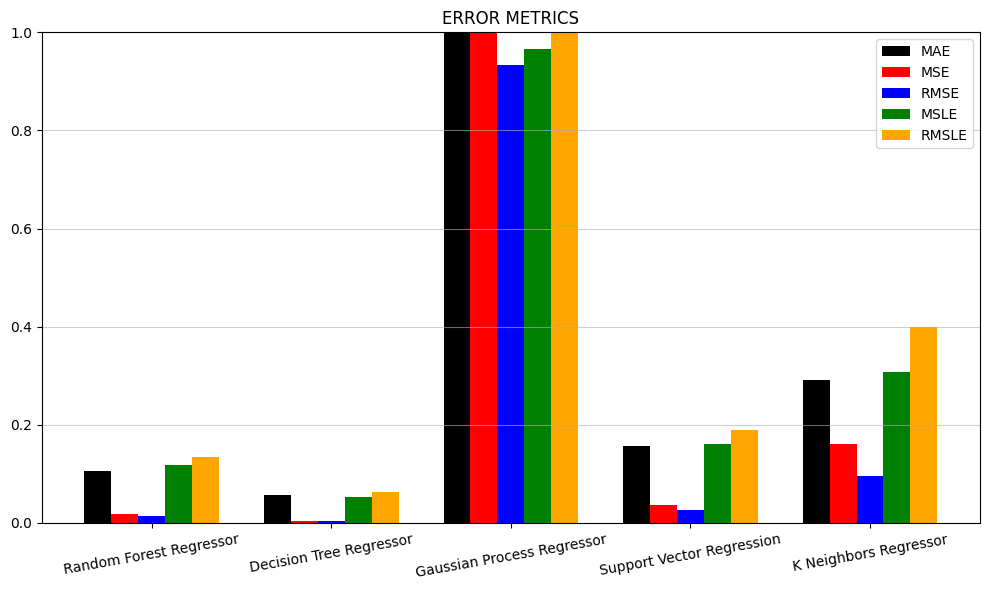

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
# Load dataset
df = pd.read_csv("Efficiency.csv")
# Input and output (example)
X = df[["Frequency_in_GHz"]]
y = df["Rad_effi_in_mag"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Initialize models (explicitly, no model list)
rf = RandomForestRegressor(random_state=42)
dt = DecisionTreeRegressor(random_state=42)
gp = GaussianProcessRegressor(random_state=42)
svm = SVR()
knn = KNeighborsRegressor()
# Train models
rf.fit(X_train, y_train)
dt.fit(X_train, y_train)
gp.fit(X_train, y_train)
svm.fit(X_train, y_train)
knn.fit(X_train, y_train)
# Predictions
y_rf = rf.predict(X_test)
y_dt = dt.predict(X_test)
y_gp = gp.predict(X_test)
y_svm = svm.predict(X_test)
y_knn = knn.predict(X_test)
# Error calculation function
def calc_errors(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    msle = mean_squared_log_error(y_true, np.maximum(y_pred, 0))
    rmsle = np.sqrt(msle)
    rmse = np.sqrt(mse)
    return mae, mse, msle, rmsle, rmse

rf_err = calc_errors(y_test, y_rf)
dt_err = calc_errors(y_test, y_dt)
gp_err = calc_errors(y_test, y_gp)
svm_err = calc_errors(y_test, y_svm)
knn_err = calc_errors(y_test, y_knn)
# Prepare data for plotting
MAE   = [rf_err[0], dt_err[0], gp_err[0], svm_err[0], knn_err[0]]
MSE   = [rf_err[1], dt_err[1], gp_err[1], svm_err[1], knn_err[1]]
RMSE  = [rf_err[2], dt_err[2], gp_err[2], svm_err[2], knn_err[2]]
MSLE  = [rf_err[3], dt_err[3], gp_err[3], svm_err[3], knn_err[3]]
RMSLE = [rf_err[4], dt_err[4], gp_err[4], svm_err[4], knn_err[4]]

labels = [
    "Random Forest Regressor",
    "Decision Tree Regressor",
    "Gaussian Process Regressor",
    "Support Vector Regression",
    "K Neighbors Regressor"
]
# Plot 
x = np.arange(len(labels))

plt.figure(figsize=(10, 6))
width=0.15
plt.bar(x - 2*width, MAE,   width=width, color="black",  label="MAE")
plt.bar(x - width,   MSE,   width=width, color="red",    label="MSE")
plt.bar(x,           RMSE,  width=width, color="blue",   label="RMSE")
plt.bar(x + width,   MSLE,  width=width, color="green",  label="MSLE")
plt.bar(x + 2*width, RMSLE, width=width, color="orange", label="RMSLE")

plt.xticks(x, labels,rotation=10)
plt.ylim(0, 1)   # Set Y-axis range from 0 to 1

plt.title("ERROR METRICS")
plt.legend()
plt.grid(axis="y",alpha=0.6)
plt.tight_layout()
plt.savefig('yaxisefficiency bar plot.png',dpi=600)

plt.show()


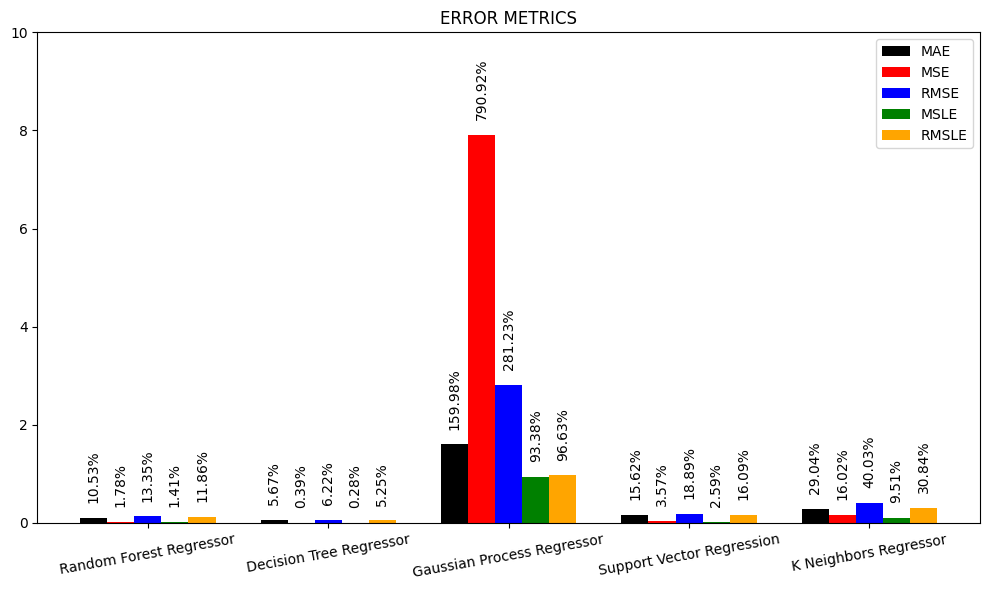

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor


# Load dataset
df = pd.read_csv("Efficiency.csv")

# Input and output
X = df[["Frequency_in_GHz"]]
y = df["Rad_effi_in_mag"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Initialize models
rf  = RandomForestRegressor(random_state=42)
dt  = DecisionTreeRegressor(random_state=42)
gp  = GaussianProcessRegressor(random_state=42)
svm = SVR()
knn = KNeighborsRegressor()

# Train models
rf.fit(X_train, y_train)
dt.fit(X_train, y_train)
gp.fit(X_train, y_train)
svm.fit(X_train, y_train)
knn.fit(X_train, y_train)

# Predictions
y_rf  = rf.predict(X_test)
y_dt  = dt.predict(X_test)
y_gp  = gp.predict(X_test)
y_svm = svm.predict(X_test)
y_knn = knn.predict(X_test)


# Error calculation function
def calc_errors(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    msle = mean_squared_log_error(y_true, np.maximum(y_pred, 0))
    rmsle = np.sqrt(msle)

    return mae, mse, rmse, msle, rmsle


rf_err  = calc_errors(y_test, y_rf)
dt_err  = calc_errors(y_test, y_dt)
gp_err  = calc_errors(y_test, y_gp)
svm_err = calc_errors(y_test, y_svm)
knn_err = calc_errors(y_test, y_knn)


# Prepare data
MAE   = [rf_err[0], dt_err[0], gp_err[0], svm_err[0], knn_err[0]]
MSE   = [rf_err[1], dt_err[1], gp_err[1], svm_err[1], knn_err[1]]
RMSE  = [rf_err[2], dt_err[2], gp_err[2], svm_err[2], knn_err[2]]
MSLE  = [rf_err[3], dt_err[3], gp_err[3], svm_err[3], knn_err[3]]
RMSLE = [rf_err[4], dt_err[4], gp_err[4], svm_err[4], knn_err[4]]

labels = [
    "Random Forest Regressor",
    "Decision Tree Regressor",
    "Gaussian Process Regressor",
    "Support Vector Regression",
    "K Neighbors Regressor"
]


# Plot
x = np.arange(len(labels))
width = 0.15

plt.figure(figsize=(10,6))

bars1 = plt.bar(x - 2*width, MAE, width=width, color="black",  label="MAE")
bars2 = plt.bar(x - width,   MSE, width=width, color="red",    label="MSE")
bars3 = plt.bar(x,           RMSE,width=width, color="blue",   label="RMSE")
bars4 = plt.bar(x + width,   MSLE,width=width, color="green",  label="MSLE")
bars5 = plt.bar(x + 2*width, RMSLE,width=width,color="orange", label="RMSLE")


# Function to add percentage labels
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.3,
            f"{height*100:.2f}%",
            ha='center',
            va='bottom',
            fontsize=10,
            rotation=90
        )

# Apply labels
add_labels(bars1)
add_labels(bars2)
add_labels(bars3)
add_labels(bars4)
add_labels(bars5)


plt.xticks(x, labels, rotation=10)
plt.ylim(0,10)

plt.title("ERROR METRICS")
plt.legend()
#plt.grid(bbox_inches="tight")
plt.tight_layout()

# Save figure if needed
#plt.savefig("%%%efficiency_bar_plot.png", dpi=600)

plt.show()

ax.spines['top'].set_visible(False): Removes the upper border.

ax.spines['right'].set_visible(False): Removes the right border.

ax.legend(frameon=False): Removes the box around the legend to keep the clean look.

ax.grid(True, linestyle='--', alpha=0.6): Adds dashed grid lines for better